# 04 Anomaly detection

Can the historian data warn the control room before a package trips, early enough to act?

Approach:

1. Learn what healthy running looks like from the first year, using Isolation Forest.
2. Build one model per equipment group (feed air compressor, PPU, expander and cold box), so an alert also says where to look.
3. Pick the alert threshold on a separate validation period, then score a test period the models have never seen.
4. Judge it the way an operations manager would: how many trips it caught, how many hours ahead, how often it cried wolf, and whether it beats the existing DCS alarms.

| Period | Dates | Use |
|---|---|---|
| Train | Oct 2024 to Sep 2025 | fit the models on healthy hours |
| Validation | Oct 2025 to Jan 2026 | choose the alert threshold |
| Test | Feb 2026 to Sep 2026 | final, untouched evaluation |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from plant_style import (apply_style, save, load, PACKAGE_COLOURS, CAUSE_COLOURS, ALERT, INK_2,
                         MODE_NAMES, RAW, PROCESSED, SPLIT_VALID, SPLIT_TEST)

apply_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

from sklearn.ensemble import IsolationForest

hourly = load("hourly_process_data").sort_values(["package_id", "timestamp"]).reset_index(drop=True)
downtime = load("downtime_events")
oplog = load("operator_log")
alarms = load("process_alarms")
trips = downtime[downtime.event_type == "Unplanned"].copy()

## Cleaning

Two fixes from notebook 02: mask the monthly O2 analyser calibration (exact 0.00 and 8.00 ppm readings while running), and fill short historian gaps from the last good value.

In [2]:
h = hourly.copy()
cal = h.operating_state.eq("RUN") & h.o2_content_ppm.isin([0.0, 8.0])
h.loc[cal, "o2_content_ppm"] = np.nan
value_cols = h.columns[3:]
h[value_cols] = h.groupby("package_id")[list(value_cols)].ffill(limit=3)
print(f"Masked {cal.sum()} calibration readings")

Masked 130 calibration readings


## Features

Each feature is something a panel operator already watches, plus its change over the last 6 hours (slow drifts matter more than levels). Two derived features take the weather out: aftercooler approach (outlet air minus cooling water temperature) and specific power (kW per Nm3 of air). O2 and CO2 go on a log scale because they sit near zero and spike by factors of ten.

In [3]:
h["approach_temp"] = h.feed_air_discharge_temp_degC - h.cooling_water_supply_temp_degC
h["specific_power"] = h.feed_air_compressor_power_kw / h.feed_air_flow_nm3h
h["log_o2"] = np.log(h.o2_content_ppm.clip(lower=0.1))
h["log_co2"] = np.log(h.ppu_outlet_co2_ppm.clip(lower=0.01))

GROUPS = {
    "Compressor": ["compressor_vibration_mm_s", "approach_temp", "specific_power"],
    "PPU": ["log_co2", "ppu_outlet_dewpoint_degC", "coldbox_dp_kpa", "log_o2"],
    "Expander": ["expander_speed_rpm", "expander_bearing_temp_degC", "expander_vibration_um", "coldbox_temp_degC"],
}
DRIFT = ["compressor_vibration_mm_s", "approach_temp", "specific_power", "log_co2", "coldbox_dp_kpa", "log_o2",
         "expander_bearing_temp_degC", "expander_vibration_um"]
g = h.groupby("package_id")
for c in DRIFT:
    h[c + "_chg6h"] = h[c] - g[c].shift(6)
group_cols = {k: v + [c + "_chg6h" for c in v if c in DRIFT] for k, v in GROUPS.items()}
features = sorted({c for cols in group_cols.values() for c in cols})

# Only score steady running: RUN now and for the previous 6 hours, so startups do not look like faults.
steady = g["operating_state"].transform(lambda s: s.eq("RUN").astype(int).rolling(7, min_periods=7).sum().eq(7))
scorable = steady & h[features].notna().all(axis=1)
print(f"{len(features)} features, {scorable.sum():,} scorable hours of {len(h):,}")

19 features, 48,385 scorable hours of 52,560


## Labels: which hours were healthy?

The models never see a label. Labels are used twice: to keep known fault periods out of the training data, and to score the results. A healthy hour is any hour that is not within 96 hours before an unplanned trip and not inside a fault the operators logged and fixed.

In [4]:
def hours_to_next_trip(df):
    out = pd.Series(np.nan, index=df.index)
    for pkg, t in trips.groupby("package_id"):
        m = df.package_id.eq(pkg)
        tt = np.sort(t.trip_time.to_numpy())
        ts = df.loc[m, "timestamp"].to_numpy()
        j = np.searchsorted(tt, ts, side="left")
        nxt = tt[np.minimum(j, len(tt) - 1)]
        out[m] = np.where(j < len(tt), (nxt - ts) / np.timedelta64(1, "h"), np.nan)
    return out

h["hours_to_trip"] = hours_to_next_trip(h)
h["in_logged_fault"] = False
for _, r in oplog.iterrows():
    h.loc[h.package_id.eq(r.package_id) & h.timestamp.between(r.fault_start, r.fault_cleared), "in_logged_fault"] = True

h["period"] = np.where(h.timestamp < SPLIT_VALID, "train", np.where(h.timestamp < SPLIT_TEST, "validation", "test"))
healthy = ~(h.hours_to_trip <= 96) & ~h.in_logged_fault
train = scorable & healthy & h.period.eq("train")
print(f"Training hours: {train.sum():,}")
print(trips.assign(period=np.where(trips.trip_time < SPLIT_VALID, "train",
                                   np.where(trips.trip_time < SPLIT_TEST, "validation", "test")))
      .groupby(["period", "cause_category"]).size().unstack(fill_value=0))

Training hours: 19,614
cause_category  Electrical  Mechanical  Process  Utility
period                                                  
test                     8          10        9        2
train                   13          16       10        3
validation               5           5        2        1


## Fit one Isolation Forest per equipment group

Each package is scaled against its own healthy medians, since NGU-C's normal is not NGU-A's normal. Isolation Forest scores how easy a point is to separate from the rest; healthy hours are hard to isolate, odd ones are easy.

Why three models and not one: with all nineteen features in one forest, a single signal moving a long way (aftercooler temperature during a cooling water loss) gets diluted by the other eighteen and scores barely above normal. Splitting by equipment keeps each signal's voice, and tells the operator which system to check.

In [5]:
med = h[train].groupby("package_id")[features].median()
iqr = h[train].groupby("package_id")[features].quantile(0.75) - h[train].groupby("package_id")[features].quantile(0.25)
Z = (h[features] - med.loc[h.package_id].to_numpy()) / iqr.loc[h.package_id].to_numpy()

models = {}
for grp, cols in group_cols.items():
    models[grp] = IsolationForest(n_estimators=300, max_samples=2048, random_state=42).fit(Z.loc[train, cols])
    h[f"score_{grp}"] = np.nan
    h.loc[scorable, f"score_{grp}"] = -models[grp].score_samples(Z.loc[scorable, cols])

## Alert logic

For a threshold quantile q, each group's threshold is the q-th percentile of its scores on healthy training hours. The risk ratio is the highest of score / threshold across the three groups; above 1.0 means anomalous. An alert needs 2 of the last 3 hours above 1.0, so a single noisy hour does not page anyone. Alert hours less than 6 hours apart merge into one alert episode.

A trip counts as caught if an alert fires in the 96 hours before it. Lead time is trip time minus the start of the first alert in that window.

In [6]:
def apply_threshold(q):
    out = h[["timestamp", "package_id", "period", "hours_to_trip", "in_logged_fault"]].copy()
    ratios = []
    for grp in GROUPS:
        thr = np.quantile(h.loc[train, f"score_{grp}"], q)
        out[f"ratio_{grp}"] = h[f"score_{grp}"] / thr
        ratios.append(f"ratio_{grp}")
    out["risk_ratio"] = out[ratios].max(axis=1)
    out["flagged_system"] = out[ratios].fillna(-np.inf).idxmax(axis=1).str.replace("ratio_", "")
    out.loc[out.risk_ratio.isna(), "flagged_system"] = None
    above = out.risk_ratio.gt(1).astype(int)
    out["alert"] = above.groupby(out.package_id).transform(lambda s: s.rolling(3, min_periods=1).sum() >= 2) & above.astype(bool)
    return out


def episodes(scored):
    a = scored[scored.alert].copy()
    new = a.groupby("package_id").timestamp.diff().gt(pd.Timedelta(hours=6)) | a.groupby("package_id").timestamp.diff().isna()
    a["episode"] = new.cumsum()
    ep = a.groupby("episode").agg(package_id=("package_id", "first"), start=("timestamp", "min"), end=("timestamp", "max"),
                                  peak_ratio=("risk_ratio", "max"), period=("period", "first"),
                                  system=("flagged_system", lambda s: s.mode().iat[0]),
                                  trip_within_96h=("hours_to_trip", lambda s: bool((s <= 96).any())),
                                  logged_fault=("in_logged_fault", "any")).reset_index(drop=True)
    ep["outcome"] = np.select([ep.trip_within_96h, ep.logged_fault], ["Warned before trip", "Fault caught by crew"], "False alarm")
    return ep


def evaluate(scored, period):
    rows = []
    for _, tr in trips.iterrows():
        p = "train" if tr.trip_time < SPLIT_VALID else "validation" if tr.trip_time < SPLIT_TEST else "test"
        if p != period:
            continue
        w = scored[scored.package_id.eq(tr.package_id) & scored.alert &
                   scored.timestamp.between(tr.trip_time - pd.Timedelta(hours=96), tr.trip_time - pd.Timedelta(hours=1))]
        al = alarms[alarms.package_id.eq(tr.package_id) &
                    alarms.timestamp.between(tr.trip_time - pd.Timedelta(hours=96), tr.trip_time - pd.Timedelta(hours=1))]
        rows.append(dict(event_id=tr.event_id, package_id=tr.package_id, trip_time=tr.trip_time,
                         cause=tr.cause_category, failure_mode=MODE_NAMES[tr.failure_mode],
                         caught=len(w) > 0,
                         model_lead_h=(tr.trip_time - w.timestamp.min()) / pd.Timedelta(hours=1) if len(w) else 0.0,
                         flagged_system=w.flagged_system.mode().iat[0] if len(w) else None,
                         dcs_alarm_lead_h=(tr.trip_time - al.timestamp.min()) / pd.Timedelta(hours=1) if len(al) else 0.0))
    return pd.DataFrame(rows)


# The DCS baseline ignores standing nuisance alarms that crews learn to tune out: any tag and alarm
# type that preceded a trip less than 25% of the time during the training year.
tr_al = alarms[alarms.timestamp < SPLIT_VALID]
share = tr_al.groupby(["tag", "alarm_type"]).preceding_downtime_event.mean()
nuisance = set(share[share < 0.25].index)
print("Nuisance alarms left out of the DCS baseline:", sorted(nuisance))
alarms = alarms[~alarms.set_index(["tag", "alarm_type"]).index.isin(nuisance)]


def months(period):
    s = h.loc[h.period.eq(period), "timestamp"]
    return (s.max() - s.min()) / pd.Timedelta(days=30.44)

Nuisance alarms left out of the DCS baseline: [('AI-216', 'H'), ('TI-206', 'H'), ('TI-212', 'H'), ('TI-303', 'H'), ('TI-306', 'H'), ('VI-213', 'H')]


## Choose the threshold on the validation period

The rule, set before looking at the test period: catch as many trips as possible while keeping false alarms to at most one per package per month. On a tie, take the stricter threshold.

In [7]:
rows = []
for q in [0.99, 0.995, 0.998, 0.999]:
    sc = apply_threshold(q)
    ev = evaluate(sc, "validation")
    ep = episodes(sc)
    ep = ep[ep.period.eq("validation")]
    rows.append(dict(q=q, trips=len(ev), caught=int(ev.caught.sum()),
                     median_lead_h=ev.loc[ev.caught, "model_lead_h"].median(),
                     false_alarms=int(ep.outcome.eq("False alarm").sum()),
                     false_per_pkg_month=ep.outcome.eq("False alarm").sum() / (3 * months("validation"))))
choice = pd.DataFrame(rows)
ok = choice[choice.false_per_pkg_month <= 1.0]
Q = ok.sort_values(["caught", "q"], ascending=[False, False]).q.iat[0]
print(f"Chosen threshold quantile: {Q}")
choice.round({"median_lead_h": 1, "false_per_pkg_month": 2})

Chosen threshold quantile: 0.998


,q,trips,caught,median_lead_h,false_alarms,false_per_pkg_month
0,0.990,13,10,23.5,34,2.81
1,0.995,13,7,17.0,17,1.40
2,0.998,13,7,17.0,5,0.41
3,0.999,13,6,17.0,1,0.08


## Test period results

In [8]:
scored = apply_threshold(Q)
test = evaluate(scored, "test")
ep = episodes(scored)
ep_test = ep[ep.period.eq("test")]

# Failure modes that develop over hours or days, per the root cause reports, vs sudden ones.
GRADUAL = ["Expander bearing", "Compressor vibration", "PPU breakthrough", "Cooling water loss"]
test["onset"] = np.where(test.failure_mode.isin(GRADUAL), "Gradual", "Sudden")
gradual = test[test.onset.eq("Gradual")]
sudden = test[test.onset.eq("Sudden")]
print(f"Test period: {len(test)} unplanned trips")
print(f"Caught in all: {test.caught.sum()} of {len(test)} ({test.caught.mean():.0%})")
print(f"Gradual failures caught: {gradual.caught.sum()} of {len(gradual)} ({gradual.caught.mean():.0%})")
print(f"Sudden failures caught: {sudden.caught.sum()} of {len(sudden)} (any catch here is an unrelated alert that happened to fall in the window)")
print(f"Caught 24 h or more ahead: {(test.model_lead_h >= 24).sum()} of {len(test)}")
print()
by_mode = test.groupby("failure_mode").agg(trips=("event_id", "size"), caught=("caught", "sum"),
                                           median_model_lead_h=("model_lead_h", lambda s: s[s > 0].median()),
                                           median_dcs_alarm_lead_h=("dcs_alarm_lead_h", lambda s: s[s > 0].median()))
by_mode.sort_values("trips", ascending=False).round(1)

Test period: 29 unplanned trips
Caught in all: 18 of 29 (62%)
Gradual failures caught: 17 of 17 (100%)
Sudden failures caught: 1 of 12 (any catch here is an unrelated alert that happened to fall in the window)
Caught 24 h or more ahead: 4 of 29



,trips,caught,median_model_lead_h,median_dcs_alarm_lead_h
failure_mode,,,,
PPU breakthrough,7,7,9.0,9.0
Expander bearing,6,6,28.5,9.0
Grid power dip,6,1,12.0,88.0
Compressor vibration,2,2,36.0,17.5
Coupling failure,2,0,NaN,NaN
Cooling water loss,2,2,4.0,4.5
Motor relay trip,2,0,NaN,NaN
PPU valve failure,2,0,NaN,NaN


In [9]:
test[["event_id", "package_id", "trip_time", "failure_mode", "caught", "model_lead_h", "flagged_system", "dcs_alarm_lead_h"]]

,event_id,package_id,trip_time,failure_mode,caught,model_lead_h,flagged_system,dcs_alarm_lead_h
0,DT-0072,NGU-C,2026-02-01 07:00:00,Expander bearing,True,10.0,Expander,5.0
1,DT-0073,NGU-B,2026-02-10 05:00:00,Expander bearing,True,10.0,Expander,2.0
2,DT-0077,NGU-C,2026-03-01 18:00:00,Compressor vibration,True,20.0,Compressor,10.0
3,DT-0078,NGU-B,2026-03-16 08:00:00,Motor relay trip,False,0.0,NaN,0.0
4,DT-0079,NGU-C,2026-03-18 12:00:00,Expander bearing,True,68.0,Expander,33.0
5,DT-0080,NGU-B,2026-03-26 19:00:00,Cooling water loss,True,5.0,Compressor,6.0
6,DT-0082,NGU-C,2026-04-10 15:00:00,Coupling failure,False,0.0,NaN,0.0
7,DT-0083,NGU-B,2026-04-23 22:00:00,Motor relay trip,False,0.0,NaN,0.0
8,DT-0084,NGU-C,2026-04-25 01:00:00,Expander bearing,True,37.0,Expander,19.0
9,DT-0085,NGU-C,2026-05-05 00:00:00,PPU valve failure,False,0.0,NaN,0.0


Does the model point at the right equipment? Compressor and expander faults should be flagged by those models, PPU breakthroughs by the PPU model, and a cooling water loss by the compressor model (it shows up as aftercooler temperature).

In [10]:
pd.crosstab(test.loc[test.caught, "failure_mode"], test.loc[test.caught, "flagged_system"])

flagged_system,Compressor,Expander,PPU
failure_mode,,,
Compressor vibration,2,0,0
Cooling water loss,2,0,0
Expander bearing,0,6,0
Grid power dip,1,0,0
PPU breakthrough,0,0,7


## How often does it cry wolf?

In [11]:
outcomes = ep_test.outcome.value_counts()
print(outcomes)
fa = outcomes.get("False alarm", 0)
print(f"\nFalse alarms: {fa} in {months('test'):.1f} months across 3 packages = "
      f"{fa / (3 * months('test')):.2f} per package per month")
ep_test.sort_values("start")[["package_id", "start", "end", "system", "peak_ratio", "outcome"]].round({"peak_ratio": 2})

outcome
Warned before trip      17
False alarm              7
Fault caught by crew     3
Name: count, dtype: int64

False alarms: 7 in 7.9 months across 3 packages = 0.29 per package per month


,package_id,start,end,system,peak_ratio,outcome
47,NGU-B,2026-02-09 19:00:00,2026-02-10 04:00:00,Expander,1.29,Warned before trip
96,NGU-C,2026-02-28 22:00:00,2026-03-01 17:00:00,Compressor,1.22,Warned before trip
21,NGU-A,2026-03-15 07:00:00,2026-03-16 08:00:00,Expander,1.25,Fault caught by crew
97,NGU-C,2026-03-15 16:00:00,2026-03-18 11:00:00,Expander,1.29,Warned before trip
48,NGU-B,2026-03-26 14:00:00,2026-03-26 18:00:00,Compressor,1.18,Warned before trip
98,NGU-C,2026-03-30 13:00:00,2026-03-30 13:00:00,Expander,1.00,False alarm
22,NGU-A,2026-04-10 22:00:00,2026-04-10 22:00:00,Expander,1.03,False alarm
23,NGU-A,2026-04-19 23:00:00,2026-04-19 23:00:00,Expander,1.03,False alarm
99,NGU-C,2026-04-23 12:00:00,2026-04-25 00:00:00,Expander,1.29,Warned before trip
100,NGU-C,2026-05-26 02:00:00,2026-05-26 11:00:00,PPU,1.33,Warned before trip


"Fault caught by crew" episodes are not false alarms. They line up with shift log entries where the operators spotted a developing fault and fixed it before a trip (early PPU switchover, unloading the compressor, changing over to the standby expander). The model saw the same thing the crew saw.

## Model vs the existing DCS alarms

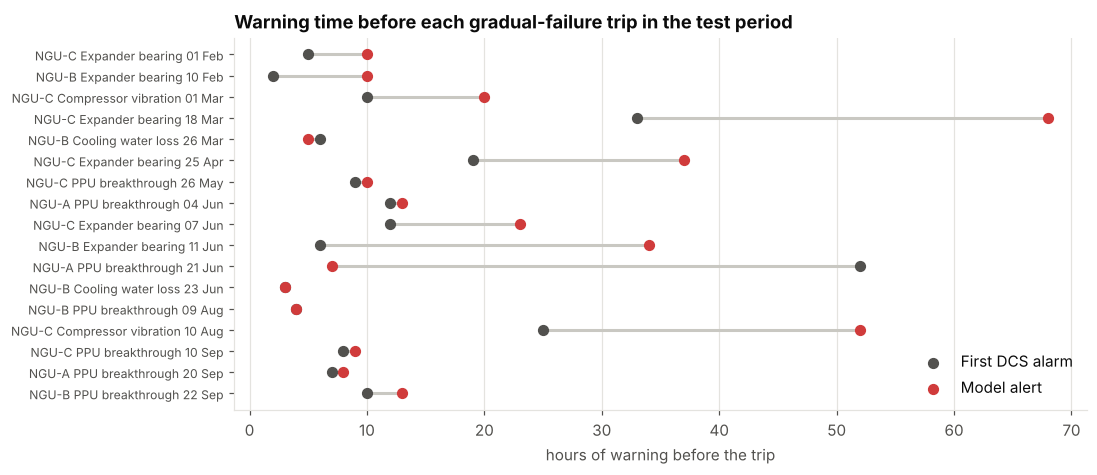

Median extra warning over the first DCS alarm: 3 h
failure_mode
Compressor vibration    18.5
Cooling water loss      -0.5
Expander bearing        14.5
PPU breakthrough         1.0
Name: median extra hours, dtype: float64


In [12]:
both = gradual
fig, ax = plt.subplots(figsize=(10, 4.4))
y = np.arange(len(both))
ax.hlines(y, both.dcs_alarm_lead_h, both.model_lead_h, color="#c9c8c2", lw=2)
ax.scatter(both.dcs_alarm_lead_h, y, color=INK_2, s=40, label="First DCS alarm", zorder=3)
ax.scatter(both.model_lead_h, y, color=ALERT, s=40, label="Model alert", zorder=3)
ax.set_yticks(y, [f"{r.package_id} {r.failure_mode} {r.trip_time:%d %b}" for r in both.itertuples()], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("hours of warning before the trip")
ax.set_title("Warning time before each gradual-failure trip in the test period")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save(fig, "04_model_vs_dcs_lead_time")
plt.show()

gain = (both.model_lead_h - both.dcs_alarm_lead_h)
print(f"Median extra warning over the first DCS alarm: {gain.median():.0f} h")
print(both.assign(extra_h=gain).groupby("failure_mode").extra_h.median().rename("median extra hours"))

## What an alert looks like on the trend

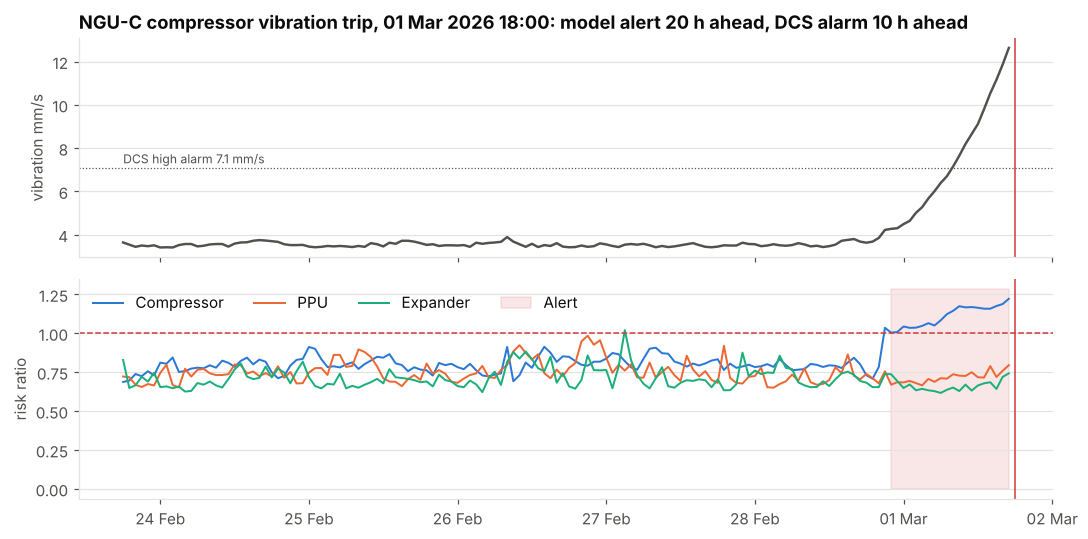

In [13]:
ex = test[test.failure_mode.eq("Compressor vibration") & test.caught].iloc[0]
w = scored[scored.package_id.eq(ex.package_id) &
           scored.timestamp.between(ex.trip_time - pd.Timedelta(days=6), ex.trip_time + pd.Timedelta(days=1))]
raw = h[h.package_id.eq(ex.package_id) & h.timestamp.between(w.timestamp.min(), w.timestamp.max())]

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(raw.timestamp, raw.compressor_vibration_mm_s.where(raw.operating_state.eq("RUN")), color=INK_2)
axes[0].axhline(7.1, color=INK_2, lw=0.8, ls=":")
axes[0].text(raw.timestamp.min(), 7.3, "DCS high alarm 7.1 mm/s", color=INK_2, fontsize=8)
axes[0].set_ylabel("vibration mm/s")
for grp, col in zip(GROUPS, ["#2a78d6", "#eb6834", "#1baf7a"]):
    axes[1].plot(w.timestamp, w[f"ratio_{grp}"], color=col, label=grp, lw=1.3)
axes[1].axhline(1, color=ALERT, lw=1, ls="--")
axes[1].fill_between(w.timestamp, 0, w.risk_ratio.max() * 1.05, where=w.alert, color=ALERT, alpha=0.12, label="Alert")
axes[1].set_ylabel("risk ratio")
axes[1].legend(ncol=4, loc="upper left")
for ax in axes:
    ax.axvline(ex.trip_time, color=ALERT, lw=1)
axes[0].set_title(f"{ex.package_id} compressor vibration trip, {ex.trip_time:%d %b %Y %H:%M}: "
                  f"model alert {ex.model_lead_h:.0f} h ahead, DCS alarm {ex.dcs_alarm_lead_h:.0f} h ahead")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.tight_layout()
save(fig, "04_alert_example")
plt.show()

## Export scores for the dashboard

In [14]:
PROCESSED.mkdir(parents=True, exist_ok=True)
scored["date"] = scored.timestamp.dt.normalize()
daily_risk = scored.groupby(["date", "package_id"]).agg(
    max_risk_ratio=("risk_ratio", "max"),
    alert_hours=("alert", "sum"),
    flagged_system=("flagged_system", lambda s: s[scored.loc[s.index, "risk_ratio"].gt(1)].mode().iat[0]
                    if scored.loc[s.index, "risk_ratio"].gt(1).any() else None),
    period=("period", "first"),
).reset_index()
# High: a persistent alert fired that day. Medium: the score crossed 1.0 at least once without
# persisting, worth a look on the trend screen. Low: everything else.
daily_risk["risk_level"] = np.select([daily_risk.alert_hours > 0, daily_risk.max_risk_ratio > 1.0],
                                     ["High", "Medium"], "Low")
daily_risk.to_csv(PROCESSED / "anomaly_scores_daily.csv", index=False)
ep.to_csv(PROCESSED / "alert_episodes.csv", index=False)
test.to_csv(PROCESSED / "test_trip_evaluation.csv", index=False)
print(daily_risk.risk_level.value_counts())

risk_level
Low       1881
High       166
Medium     143
Name: count, dtype: int64


## Findings

In [15]:
mech = gradual[gradual.cause.eq("Mechanical") & gradual.caught]
mech_gain = (mech.model_lead_h - mech.dcs_alarm_lead_h).median()
print(f"1. On the unseen test period the model caught {gradual.caught.sum()} of {len(gradual)} gradual failures "
      f"({gradual.caught.mean():.0%}) and {test.caught.sum()} of {len(test)} unplanned trips in all ({test.caught.mean():.0%}).")
print(f"2. Mechanical faults were flagged a median {mech.model_lead_h.median():.0f} h ahead, "
      f"{mech_gain:.0f} h earlier than the first DCS alarm. PPU breakthroughs were flagged "
      f"{test.loc[test.failure_mode.eq('PPU breakthrough') & test.caught, 'model_lead_h'].median():.0f} h ahead, "
      f"about the same time as the CO2 alarm.")
print(f"3. False alarms: {fa / (3 * months('test')):.2f} per package per month. "
      f"{outcomes.get('Fault caught by crew', 0)} more alerts matched faults the crew fixed before a trip.")
print("4. Sudden failures (power dips, relay trips, coupling and valve failures) give no warning in process data. "
      "No model on this data can catch them; they need electrical protection and maintenance strategy, not analytics.")

1. On the unseen test period the model caught 17 of 17 gradual failures (100%) and 18 of 29 unplanned trips in all (62%).
2. Mechanical faults were flagged a median 28 h ahead, 14 h earlier than the first DCS alarm. PPU breakthroughs were flagged 9 h ahead, about the same time as the CO2 alarm.
3. False alarms: 0.29 per package per month. 3 more alerts matched faults the crew fixed before a trip.
4. Sudden failures (power dips, relay trips, coupling and valve failures) give no warning in process data. No model on this data can catch them; they need electrical protection and maintenance strategy, not analytics.
